# Computer Vision (MSAI6330) - Assignment 1

Image smoothing, noise reduction, edge detection and Laplacian pyramid blending with Python and OpenCV.

## Setup: imports and image paths

In [33]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

IMG_DIR = Path("images")
UNI_PATH = IMG_DIR / "uni.jpeg"
APPLE_PATH = IMG_DIR / "apple.jpg"
ORANGE_PATH = IMG_DIR / "orange.jpg"

for p in (UNI_PATH, APPLE_PATH, ORANGE_PATH):
    assert p.exists(), f"Missing image: {p}"

print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

OpenCV 5.0.0 | NumPy 2.5.4


In [34]:
def show(images, titles, cmap=None, figsize=(12, 5)):
    """Display images side by side. BGR colour images are converted to RGB."""
    _, axes = plt.subplots(1, len(images), figsize=figsize)
    axes = np.atleast_1d(axes)
    for ax, img, title in zip(axes, images, titles):
        if img.ndim == 3:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(img, cmap=cmap or "gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## Task 1: Image Loading and Grayscale Conversion

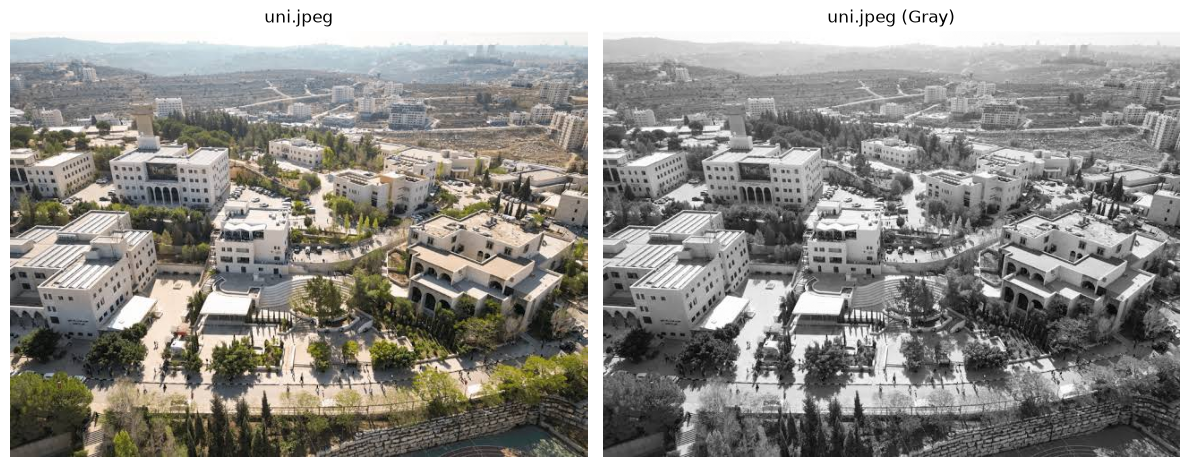

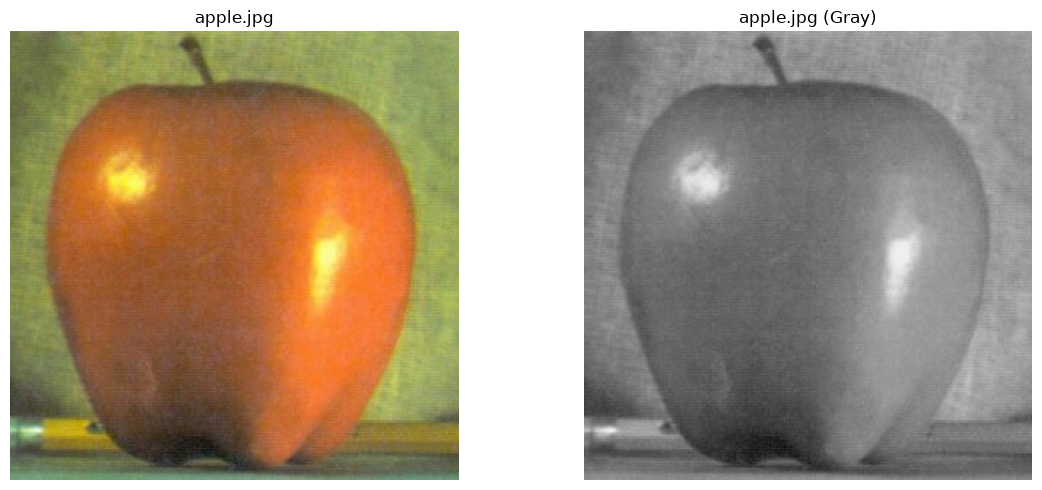

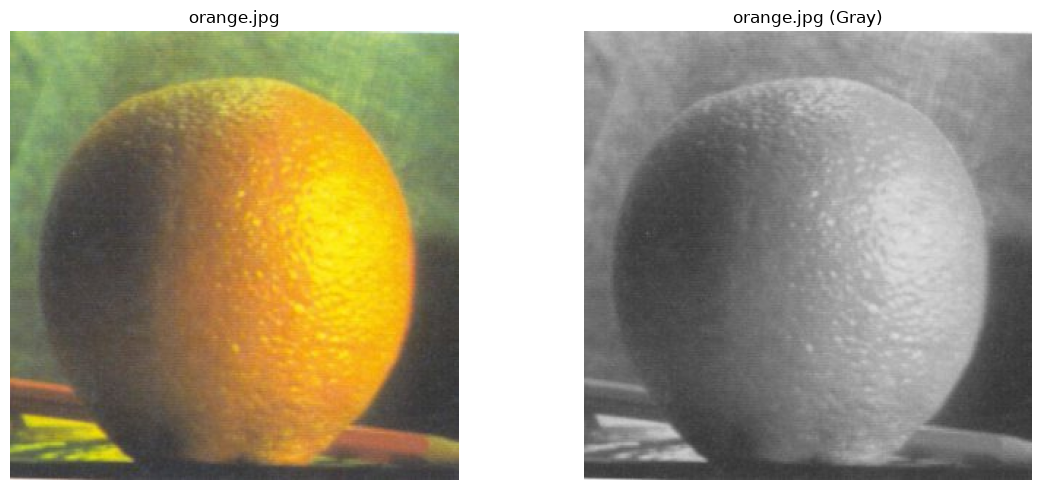

In [35]:
gray_images = []
colored_images = []
paths = [UNI_PATH, APPLE_PATH, ORANGE_PATH]
for i in range(3):
     p = paths[i]
     # before and after images in gray scale
     img = cv2.imread(str(p))
     gray = cv2.imread(str(p), 0)
     # store the prcessed images in a list with their names
     gray_images.append((gray, f"{p.name} (Gray)"))
     colored_images.append((img, f"{p.name} (Original)"))
     show([img, gray], [p.name, f"{p.name} (Gray)"])

# Canny Algorithm use from OpenCv

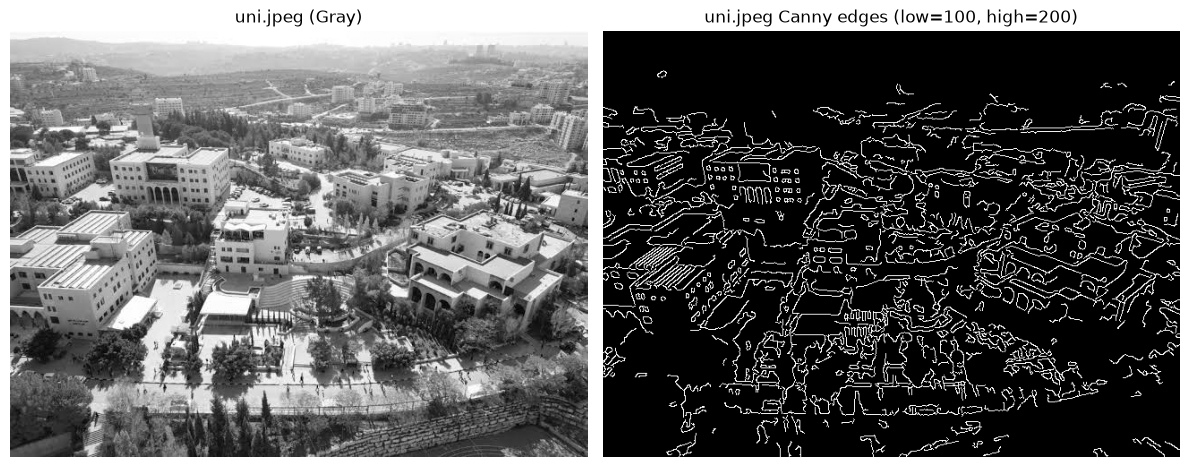

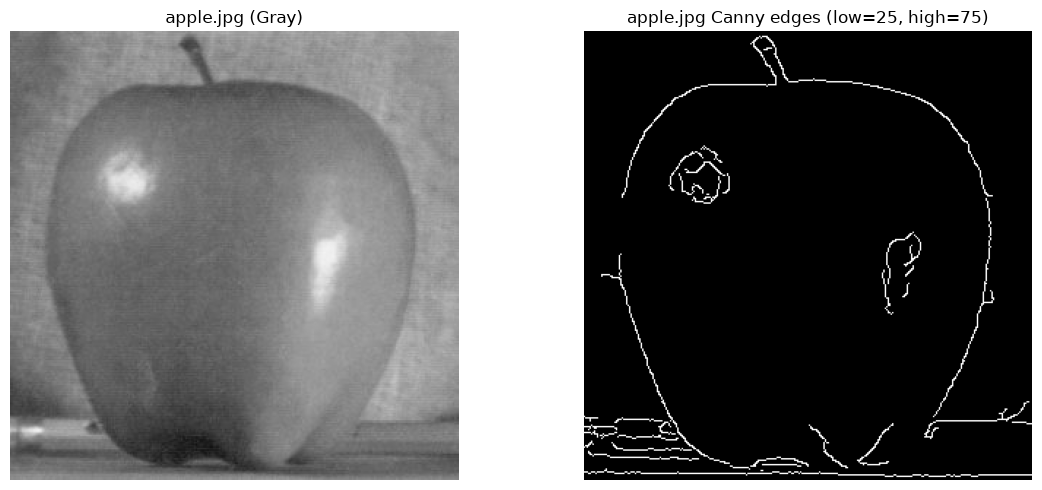

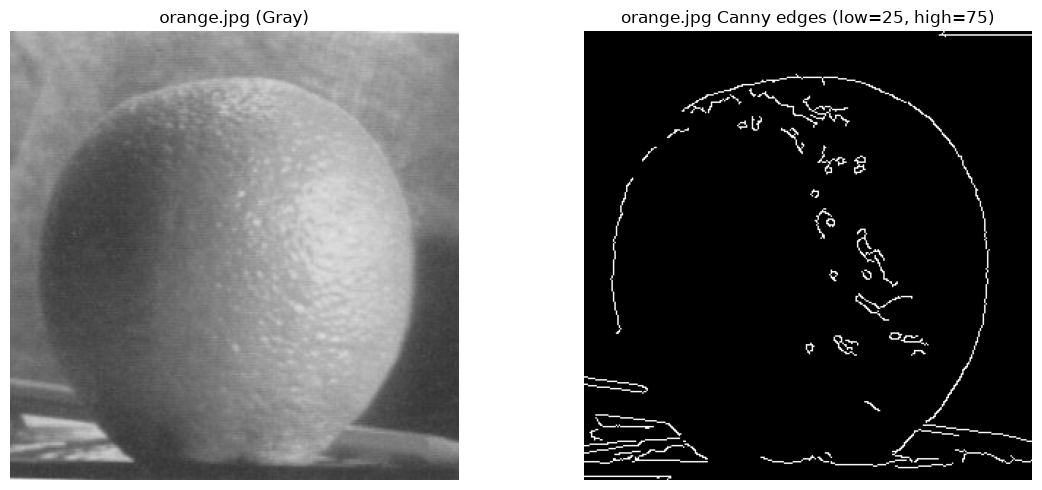

In [48]:
# per-image (lower, upper) thresholds, tuned by eye: uni has strong contrast,
# apple/orange are low-contrast so they need much lower thresholds
thresholds = {
    "uni.jpeg": (100, 200),
    "apple.jpg": (25, 75),
    "orange.jpg": (25, 75),
}

for gray, title in gray_images:
    name = title.split(" ")[0]
    low, high = thresholds[name]
    # light Gaussian blur first: Canny does not smooth the input itself
    blurred = cv2.GaussianBlur(gray, (5, 5), 1.4)
    edges = cv2.Canny(blurred, low, high)
    show([gray, edges], [title, f"{name} Canny edges (low={low}, high={high})"])

### Task 2 Discussion: Canny Edge Detection

**Effect on the images.** Canny turns each grayscale image into a thin black-and-white edge map. Flat areas become black and only the places where brightness changes sharply are kept. For `uni.jpeg` this shows the buildings, roads and trees. For `apple.jpg` and `orange.jpg` it shows the outline of the fruit, the stem and the table edge. The shapes are kept, but the shading is lost. A light Gaussian blur is applied first to reduce noise.

**Thresholds used.**

| Image | Lower | Upper |
|---|---|---|
| `uni.jpeg` | 100 | 200 |
| `apple.jpg` | 25 | 75 |
| `orange.jpg` | 25 | 75 |

`uni.jpeg` has strong contrast, so higher thresholds work to remove the noisy edges from the image. The apple and orange images are low-contrast, so with (100, 200) edges are discarded, thus we use a lower threshold amount to bring out a silhouette of the fruits here.

**Effect of changing the thresholds.** Pixels with a gradient above the upper threshold are always edges, pixels below the lower threshold are never edges, and pixels in between are kept only if they touch a strong edge.

- **Lower thresholds:** more edges, but also more sensitive to texture and noise
- **Higher thresholds:** more concise but could lose actual signals